# Warcraft III — кои единици има на screenshot-а?

**Версия 2** на проекта: входът е **цял screenshot от играта** (класическа графика), а изходът е списък
с единиците на него, например *"Human Footman, Orc Grunt, Undead Ghoul"*.

Това е **multi-label класификация** — една снимка може да има няколко етикета. Тя е обяснена в
[fastbook, глава 6](https://github.com/fastai/fastbook/blob/master/06_multicat.ipynb) и се различава от
Lesson 1 само на три места:

| | Lesson 1 (един етикет) | Тук (много етикети) |
|---|---|---|
| блок за изхода | `CategoryBlock` | `MultiCategoryBlock` |
| последен слой | softmax (сборът е 100%) | sigmoid (всяка единица отделно 0–100%) |
| метрика | `error_rate` | `accuracy_multi`, `F1ScoreMulti` |

Моделът познава **48 единици** — всички обикновени единици на 4-те раси (без героите).

## 1. Данните

Снимките не са от интернет, а **направени от самата игра**. Картата в `game_capture/dataset_trigger.j`
слага 1–6 случайни единици на случайно място (случайни цветове, посоки, анимации, ден/нощ, понякога сграда),
а `game_capture/capture.py` прави screenshot и записва кои единици има.

Затова етикетите са **винаги верни** — не е нужно ръчно почистване като във версия 1.
Всяка карта е отделен файл с име `<карта>_<номер>.jpg`.

In [1]:
from fastai.vision.all import *

df = pd.read_csv('data/labels.csv')
df['map'] = df['fname'].str.rsplit('_', n=1).str[0]
df.head()

C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,fname,labels,map
0,map1_0000.jpg,Night Elf Druid of the Talon;Orc Kodo Beast;Orc Raider,map1
1,map1_0001.jpg,Human Footman;Human Sorceress;Human Spell Breaker;Tauren Spirit Walker;Troll Headhunter,map1
2,map1_0002.jpg,Human Footman;Night Elf Huntress;Troll Headhunter;Undead Necromancer,map1
3,map1_0003.jpg,Night Elf Faerie Dragon;Troll Headhunter;Undead Acolyte,map1
4,map1_0004.jpg,Orc Raider,map1


In [2]:
print(df['map'].value_counts())
df['labels'].str.split(';').explode().value_counts()

map
map1    800
map3    799
map4    796
map2    766
Name: count, dtype: int64


labels
Night Elf Druid of the Talon    441
Night Elf Druid of the Claw     434
Troll Headhunter                416
Undead Obsidian Statue          253
Orc Raider                      241
Human Footman                   238
Troll Batrider                  238
Undead Abomination              229
Night Elf Chimaera              227
Human Priest                    223
Night Elf Archer                220
Orc Demolisher                  220
Human Peasant                   219
Troll Witch Doctor              219
Night Elf Glaive Thrower        218
Human Knight                    215
Human Mortar Team               215
Human Dragonhawk Rider          214
Undead Destroyer                213
Undead Frost Wyrm               211
Orc Kodo Beast                  208
Human Gryphon Rider             208
Undead Banshee                  208
Undead Ghoul                    208
Night Elf Huntress              206
Undead Necromancer              206
Night Elf Hippogryph Rider      206
Tauren Spirit Walker 

## 2. Честна проверка: validation от карта, която моделът не е виждал

Ако разделим снимките случайно, validation ще има същите карти като обучението и резултатът ще е
по-добър от реалния. Затова **цяла карта** остава само за проверка (както в fastbook се пази отделна
папка `valid`).

Имаме 4 карти: map1 и map4 са Lordaeron Summer (трева и пръст), map2 е Northrend (сняг и лед),
map3 е Ashenvale (гора). За проверка оставяме **map4**: такъв терен моделът е виждал (map1), но самата
карта — никога. Така при обучението има и от трите вида терен.

In [3]:
valid_map = 'map4'   # Lordaeron Summer like map1, but a map the model never sees in training
df['is_valid'] = df['map'] == valid_map
valid_map

'map4'

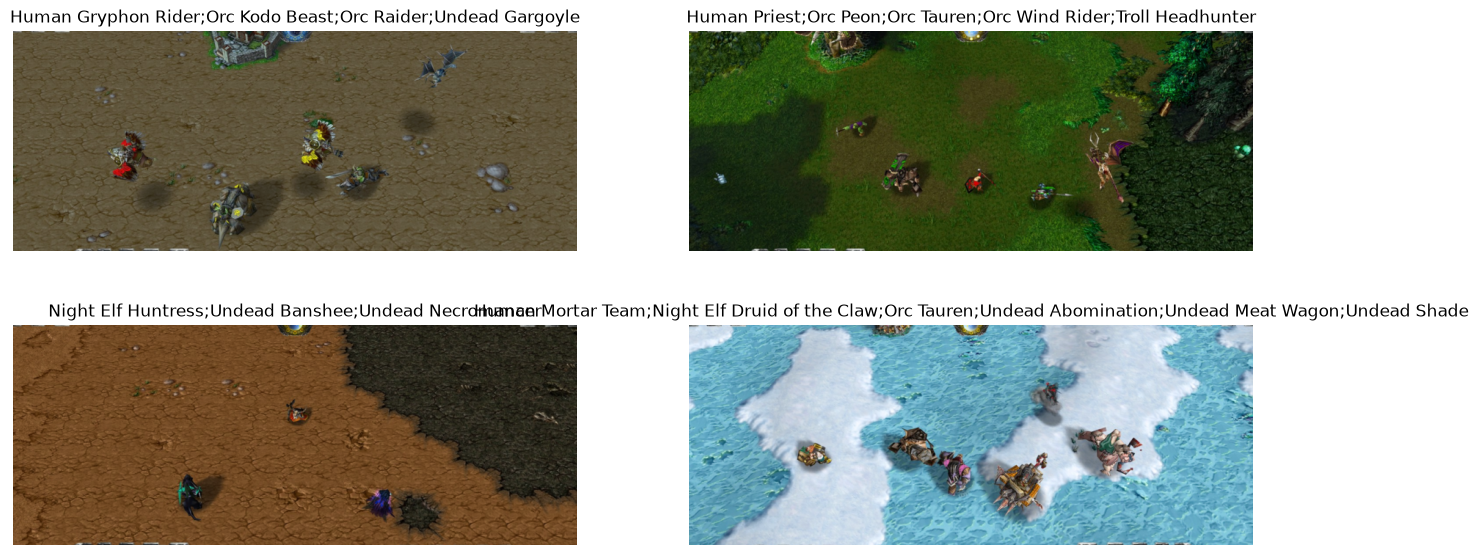

In [4]:
def crop_ui(img: PILImage):
    "Cut off the top bar and the bottom panel of the game UI (docs/index.html crops the same way)"
    w, h = img.size
    return img.crop((0, int(h * 30 / 720), w, int(h * 530 / 720)))

dls = DataBlock(
    blocks=(ImageBlock, MultiCategoryBlock),
    get_x=ColReader('fname', pref='data/screens/'),
    get_y=ColReader('labels', label_delim=';'),
    splitter=ColSplitter('is_valid'),
    item_tfms=[Transform(crop_ui), Resize((300, 768), method='squish')],
    batch_tfms=aug_transforms(max_rotate=0, max_zoom=1, max_warp=0)
).dataloaders(df, bs=16)

dls.show_batch(max_n=4, figsize=(16, 7))

Първо **изрязваме интерфейса на играта** — горната лента и долния панел (около 30% от екрана). В тях няма
единици, а заемат пиксели. Остава игралното поле 1280×500, което смаляваме до 768×300 (а не 224×224 като в
Lesson 1): единиците на цял екран са малки и при 224 пиксела биха се превърнали в няколко точки. 768×300 е
толкова пиксели, колкото 640×360, т.е. обучението не е по-бавно, но единиците стават с 20% по-големи.

Augmentation-ът е само огледално обръщане и осветление: без завъртане и zoom, за да не изрежем единица от
края на снимката.

## 3. Обучение

Първият опит (6 епохи, скоростта по подразбиране 2e-3) даде F1 0.38 и загубата още падаше — моделът не беше
доучен. Затова учим **15 епохи**.

Каква **скорост на учене** (learning rate)? Във fastbook глава 5 тя се избира с `lr_find`. Неговото
предложение се мени от пускане на пускане, защото последният слой започва със случайни тегла. При един
предишен опит използвахме предложението му директно и обучението **се разпадна**: всички тегла станаха `NaN`.
Затова учим с проверената скорост **2e-3** (близо до предложението тук) и добавяме два callback-а:
- `SaveModelCallback` пази епохата с най-ниска загуба на validation и я зарежда накрая;
- `TerminateOnNaNCallback` спира веднага, ако загубата стане `NaN`.

C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\timm\models\_factory.py:175: UserWarning: Mapping deprecated model name convnext_tiny_in22k to current convnext_tiny.fb_in22k.
  model = create_fn(


<div></div>

SuggestedLRs(valley=0.0030199517495930195)

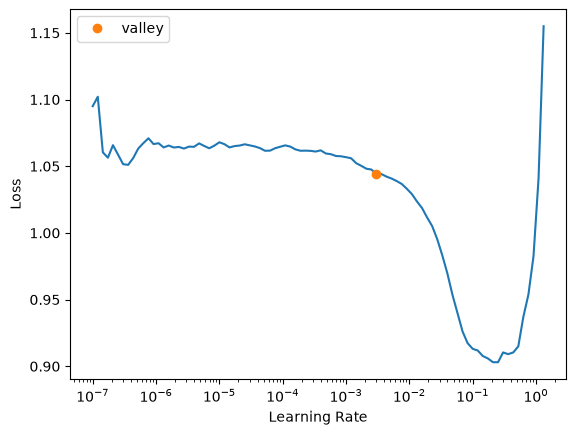

In [5]:
learn = vision_learner(dls, 'convnext_tiny_in22k',
                       metrics=[partial(accuracy_multi, thresh=0.5), F1ScoreMulti(average='macro')])
learn.lr_find()

In [6]:
learn.fine_tune(15, 2e-3, cbs=[SaveModelCallback(monitor='valid_loss'), TerminateOnNaNCallback()])

epoch,train_loss,valid_loss,accuracy_multi,f1_score,time
0,0.710989,0.300788,0.924806,0.011366,03:20


Better model found at epoch 0 with valid_loss value: 0.30078765749931335.


epoch,train_loss,valid_loss,accuracy_multi,f1_score,time
0,0.338749,0.260727,0.928261,0.000963,08:20
1,0.282586,0.247128,0.928261,0.000369,08:05
2,0.255138,0.231635,0.928837,0.015730,08:06
3,0.221764,0.208439,0.932449,0.106048,08:05
4,0.186308,0.188280,0.938547,0.220898,08:05
5,0.160342,0.160468,0.945561,0.354081,08:04
6,0.139833,0.149443,0.948780,0.412731,08:05
7,0.120080,0.144040,0.949827,0.438012,08:10
8,0.107286,0.136338,0.952863,0.487677,08:04
9,0.094921,0.134413,0.953073,0.492379,08:04


Better model found at epoch 0 with valid_loss value: 0.26072657108306885.


Better model found at epoch 1 with valid_loss value: 0.2471282184123993.


...

Better model found at epoch 7 with valid_loss value: 0.14404019713401794.


Better model found at epoch 8 with valid_loss value: 0.13633763790130615.


Better model found at epoch 9 with valid_loss value: 0.1344129890203476.


Better model found at epoch 10 with valid_loss value: 0.12929803133010864.


Better model found at epoch 11 with valid_loss value: 0.12662853300571442.


Таблицата свършва на **епоха 11, а не 14**: обучението спря по-рано без грешка. Най-вероятно загубата
отново стана `NaN` в епоха 12 и `TerminateOnNaNCallback` го спря (той не пише нищо), а `SaveModelCallback`
зареди най-добрата епоха — 11, с validation loss 0.127. Точно затова сложихме двата callback-а.
Загубата на validation падаше до самия край, т.е. моделът още не е "наситен".

**Внимание:** `accuracy_multi` гледа всяка от 48-те единици поотделно. На снимка с 3 единици моделът може
да каже "няма я" за останалите 45 и пак да има 94% — затова гледаме и **F1** (колко от истинските
единици намира и колко от намерените са верни).

## 4. Какъв праг (threshold)?

Sigmoid дава число 0–1 за всяка единица. Над прага казваме "има я". Както в fastbook глава 6,
пробваме различни прагове върху validation set-а:

best threshold: 0.19999998807907104


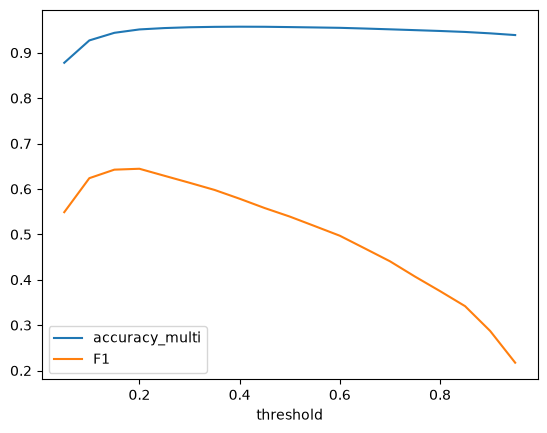

In [7]:
from sklearn.metrics import f1_score

preds, targs = learn.get_preds()
xs = torch.linspace(0.05, 0.95, 19)
accs = [accuracy_multi(preds, targs, thresh=t, sigmoid=False) for t in xs]
f1s = [f1_score(targs, preds > t, average='macro', zero_division=0) for t in xs]
plt.plot(xs, accs, label='accuracy_multi'); plt.plot(xs, f1s, label='F1'); plt.legend(); plt.xlabel('threshold')
threshold = float(xs[int(np.argmax(f1s))])
print('best threshold:', threshold)

## 5. Кои единици познава добре и кои — не?

- **recall** — от всички пъти, когато единицата е на снимката, в колко % моделът я намира;
- **precision** — когато моделът каже "тук има X", в колко % е прав.

In [8]:
found = preds > threshold
tp = (found & (targs == 1)).sum(0).float()
per_unit = pd.DataFrame({'unit': list(dls.vocab),
                         'recall': (tp / targs.sum(0)).numpy(),
                         'precision': (tp / found.sum(0).clamp(min=1)).numpy()}).round(2)
per_unit.sort_values('recall')

,unit,recall,precision
43,Undead Ghoul,0.22,0.29
27,Orc Peon,0.24,0.37
25,Orc Grunt,0.29,0.54
6,Human Peasant,0.31,0.42
8,Human Rifleman,0.32,0.89
31,Orc Wind Rider,0.33,0.57
37,Undead Acolyte,0.36,0.52
11,Human Spell Breaker,0.43,0.92
2,Human Footman,0.46,0.43
35,Troll Witch Doctor,0.46,0.32


C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


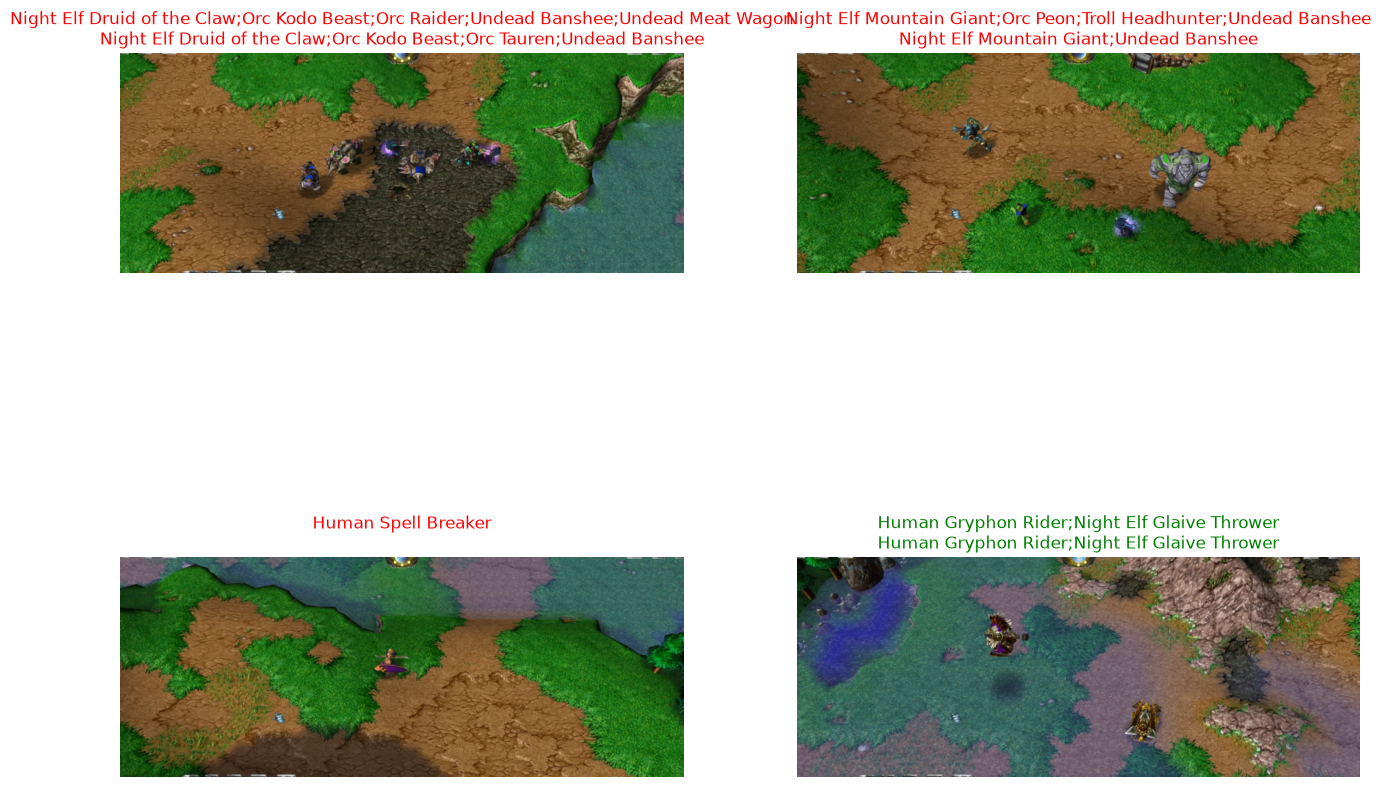

In [9]:
learn.show_results(max_n=4, figsize=(16, 12))

## 6. Проба с истински screenshot

Ако сте направили screenshot-и от истинска игра (бутон **Print Screen** в Warcraft III ги записва в
`Documents\Warcraft III\Screenshots`), сложете ги в папка `my_screenshots/` и пуснете:

In [10]:
for f in get_image_files('my_screenshots')[:5] if Path('my_screenshots').exists() else []:
    _, found_units, probs = learn.predict(f)
    print(f.name, [u for u, p in zip(dls.vocab, probs) if p > threshold])

## 7. Export за сайта (GitHub Pages)

Моделът работи директно в браузъра (вижте README):
- **ONNX** — общ формат, който JavaScript може да пусне с `onnxruntime-web`;
- **quantization** (int8) смалява файла около 3 пъти — GitHub не приема файлове над 100 MB;
- `docs/model.json` казва на страницата имената на единиците, размера на снимката и прага;
- няколко снимки от validation картата стават примери на сайта.

In [11]:
import json, shutil
from onnxruntime.quantization import quantize_dynamic, QuantType

learn.export('model.pkl')
learn.model.eval().cpu()
torch.onnx.export(learn.model, torch.randn(1, 3, 300, 768), 'model.onnx',
                  input_names=['image'], output_names=['logits'], dynamo=False)
quantize_dynamic('model.onnx', 'docs/model.onnx', weight_type=QuantType.QInt8,
                 op_types_to_quantize=['MatMul', 'Gemm'], per_channel=True)

examples = df[df['map'] == valid_map]['fname'].head(8).tolist()
shutil.rmtree('docs/examples', ignore_errors=True)
Path('docs/examples').mkdir()
for f in examples: shutil.copy(f'data/screens/{f}', 'docs/examples')

Path('docs/model.json').write_text(json.dumps({
    'labels': list(dls.vocab), 'multi_label': True, 'threshold': threshold,
    'height': 300, 'width': 768, 'crop_top': 30 / 720, 'crop_bottom': 530 / 720,   # same as crop_ui
    'examples': examples,
    'example_labels': {f: df.set_index('fname').loc[f, 'labels'].split(';') for f in examples}}))   # for the gallery

for f in ['model.pkl', 'model.onnx', 'docs/model.onnx']: print(f, Path(f).stat().st_size // 1_000_000, 'MB')

C:\Users\bobia\AppData\Local\Temp\ipykernel_30432\2215770908.py:6: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(learn.model, torch.randn(1, 3, 300, 768), 'model.onnx',


model.pkl 114 MB
model.onnx 114 MB
docs/model.onnx 34 MB
